M at H = 0 : -1999.781859949665  A/m
Sample moment mi =  -0.001999781859949665 A m^2


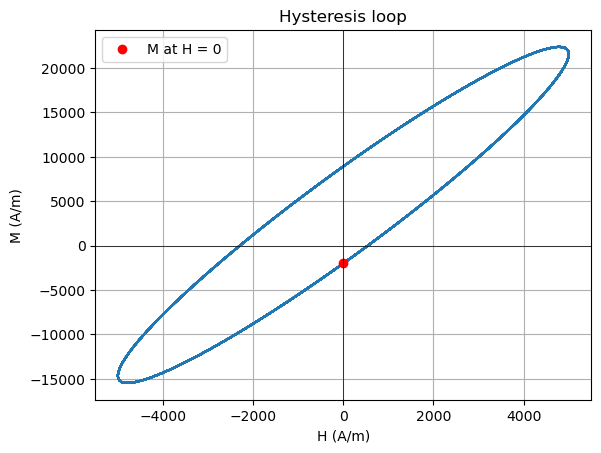

In [2]:
# This code is for signal processing for a magnetometer. 
# It will take as input 1 csv file with the structure:
#
# Time(s) | CH1 (V) | CH2 (V) 
# 
# Where:
# - CH1 is the raw pickup coil voltage
# - CH2 is the raw voltage powering an electromagnet coil (measured accross a resistor in series)
# - Time is just the time associated with each signal
#
# If the CSV outputted isnt of this form, the csv should be changed.
#
# The whole simulation runs in SI units and will output hysterysis plots in SI units (scaled appropriately)
#
# The aim of this program is to create a hysterysis loop to extract atomic magnetic moment mi of sample
#

'''
MY ORIGINAL PLAN 
1. Import libraries required such as numpy, mapplotlib, scipy
2. Define Variables:
    - N_el: number of turns in electromagnet coil
    - Np: Number of turns in the pickup coil
    - l: length of the electromagnet coil
    - B(0): background magnetisation
    - R: Resistor value (the one in series with the electromagnet coil)
    - A: Area of the pickup coil (m^2)
    - mu0: vacuum magnetic permeability (SI units)
    - V: Volume of the sample
    
3. Import data from csv (in the same folder)

    - - - BEGIN H(t) COMPUTATUION (The electromagnet bit CH2) - - - 
4. Compute I(t) array from I(t) = V(t) / R
5. Compute B(t) array from B(t) = mu0 * I(t) * N / l
6. Compute H(t) array from H(t) = B(t) / mu0

    - - - BEGIN M(t) COMPUTATION (the pickup coil bit CH1) - - -
First we will compute additional array V -> dB/dt
7. Create an array dB/dt = - V(t) / (Np * A)
6. Call integrate function cumulative_simpsons rule for creating an additional array of B(t) - B(0)
7. Create an addittional array which represents B(t) = B(0) - int[V(t)dt]
8. Create final array M(t) = (B(t)/mu0) - H(t)
9. print mi to screen with mi = M(t) * Volume of sample

    - - - PLOT Hysterysis Loop - - -
    H(t) vs M(t)
'''
# ---- 1. Imports ------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid
from scipy.integrate import cumulative_simpson 

# ---- 2. Parameters (edit these) --------------------------------------
CSV_FILE = "fake_data.csv"    # same folder as the notebook
N_el = 120        # turns in the electromagnet coil
L = 0.120      # length of electromagnet coil [m]  (120 mm)
R = 1        # series resistor [ohm] (5 A * 1 ohm = 5 V on CH2; 25 W!)
Np = 366       # 366 in the pickup coil +- 5
A = 1.0e-4     # pickup coil area [m^2]  (1 cm^2)
B0 = -2.513e-3        # known static background field B(0) [T]
V_sample = 1.0e-6     # sample volume [m^3]  (1 cm^3 = 1e-6 m^3)
mu0 = 4*np.pi*1E-7        # vacuum permeability 4PI E-7

# ---- 3. Import data --------------------------------------------------
df = pd.read_csv(CSV_FILE)             # columns:  Time (s) | CH1 (V) | CH2 (V) |
t   = df.iloc[:, 0].to_numpy(dtype=float)   # time [s] 
ch1 = df.iloc[:, 1].to_numpy(dtype=float)   # pickup coil voltage [V] (needs to be converted into a np array for integration)
ch2 = df.iloc[:, 2].to_numpy(dtype=float)   # voltage across series resistor (Electromagnet) [V]

"Note, for the code directly above we may want to start from a specific row. Oscillators usually add some starting rows. eg:"
#ch2 = df.iloc[5:, 2].to_numpy(dtype=float)   # starts from row index 5 (technically row 6 because first index is zero)

"Can Also filter by time values. Eg:"
# A. Filter the DataFrame where the first column (Time) is greater than or equal to 1.5
# Replace 'Time (s)' with your exact column header name if it differs
#filtered_df = df[df['Time (s)'] >= 1.5]

# B. Extract arrays from the filtered data
#t   = filtered_df.iloc[:, 0].to_numpy(dtype=float)
#ch1 = filtered_df.iloc[:, 1].to_numpy(dtype=float)
#ch2 = filtered_df.iloc[:, 2].to_numpy(dtype=float)

# ---- BEGIN H(t) COMPUTATION (electromagnet, CH2) ---------------------
# 4. Compute I(t) Array
I = ch2 / R                            # [A]

# 5. Field at the centre of the electromagnet coil: B(t) = mu0 * I(t) * N / L
B_el = mu0 * I * N_el / L              # [T]

# 6. Applied field: H(t) = B(t) / mu0
H = B_el / mu0                         # [A/m]

# ---- BEGIN M(t) COMPUTATION (pickup coil, CH1) -----------------------
# 7. Convert voltage to dB/dt: dB/dt = -V(t) / (Np * A)
dB_dt = -ch1 / (Np * A)                # [T/s]

# 8. Integrate dB/dt over time: gives B(t) - B(0)
#    (swap in cumulative_trapezoid if you want to compare the two methods)
B_minus_B0 = cumulative_trapezoid(dB_dt, x=t, initial=0)   # [T]
# B_minus_B0 = cumulative_simpson(dB_dt, x=t, initial=0)   # Comment line above and uncomment this to try it out

# 9. Add the background: B(t) = B(0) + [B(t) - B(0)]
B = B0 + B_minus_B0                    # [T]

# 10. Magnetisation: M(t) = B(t)/mu0 - H(t)
M = B / mu0 - H                        # [A/m]

# 11. Moment of the sample: take M where the loop crosses H = 0
j = np.argmin(np.abs(H))             # finds the index of the abs value of H element that is closest to 0
M_at_H0 = M[j]                       # [A/m] Finds the M of the same index 
mi = M_at_H0 * V_sample                # [A m^2] mi individual magnetic moment
print("M at H = 0 :", M_at_H0, " A/m")
print("Sample moment mi = " ,mi, "A m^2")

# ---- PLOT Hysteresis loop: M vs H ------------------------------------
plt.plot(H, M)
plt.plot(H[j], M_at_H0, "ro", label="M at H = 0")
plt.axhline(0, color="black", lw = 0.5)
plt.axvline(0, color="black", lw=0.5)
plt.xlabel("H (A/m)")
plt.ylabel("M (A/m)")
plt.title("Hysteresis loop")
plt.legend()
plt.grid()
plt.show()